# Chi-square minimization for a single observed spectrum

Forward modeling of a single observed spectrum by minimizing the chi-square statistics between the data and atmospheric models.

In [1]:
import seda # import the seda package
import importlib
import numpy as np
from pathlib import Path
from astropy.io import fits, ascii


    SEDA v0.8.10.dev48 package imported


## Read the spectrum

As an example here, let's read the near-infrared IRTF/SpeX spectrum for the T8 (~750 K) brown dwarf 2MASS J04151954-0935066 in [Burgasser et al. (2004)](https://ui.adsabs.harvard.edu/abs/2004AJ....127.2856B/abstract):

In [2]:
# path to the SEDA package
path_seda = Path(seda.__file__).resolve().parents[1]

# SpeX spectrum
SpeX_name = (path_seda / 'docs' / 'notebooks' / 
             'data' / '0415-0935_IRTF_SpeX.dat')
SpeX = ascii.read(SpeX_name)
wl_SpeX = SpeX['wl(um)'] # um 
flux_SpeX = SpeX['flux(erg/s/cm2/A)'] # erg/s/cm2/A
eflux_SpeX = SpeX['eflux(erg/s/cm2/A)'] # erg/s/cm2/A

## Load input data

Look at the input parameters [here](https://seda.readthedocs.io/en/latest/api.html#seda.input_parameters.InputData).

For any SEDA function, we can also see the function description directly on the notebook with the command ``help()``, e.g.:

``help(seda.input_parameters.InputData)``

In [3]:
# input spectrum
wl_spectra = wl_SpeX
flux_spectra = flux_SpeX
eflux_spectra = eflux_SpeX
# specify flux units
flux_unit = 'erg/s/cm2/A'

# resolution of input spectrum (used to convolve the model spectra)
res = 100

# distance to the target (optional and used to derive a radius)
distance = 5.71 # pc (parallax=175.2+-1.7; Dupuy-Liu2012)
edistance = 0.06 # pc

# load all the input data parameters
my_data = seda.input_parameters.InputData(wl_spectra=wl_spectra, flux_spectra=flux_spectra, 
                                          eflux_spectra=eflux_spectra, flux_unit=flux_unit, 
                                          res=res, distance=distance, edistance=edistance)


   Input data loaded successfully:
      1 spectra


Download (if not yet) the atmospheric models you want to use. 

Use the commands below to see the available atmospheric models, the links to download them, and other relevant information from models. You can read more about the model [here](https://seda.readthedocs.io/en/latest/overview.html#available-atmospheric-models).

Also consider [this tutorial](https://seda.readthedocs.io/en/latest/notebooks/tutorial_models_examination.html) to explore the free parameters in the models and their coverage.

In [4]:
# available atmospheric models
seda.models.Models().available_models

['ATMO2020',
 'BT-Settl',
 'LB23',
 'LOWZ',
 'SAND',
 'SM08',
 'Sonora_Bobcat',
 'Sonora_Cholla',
 'Sonora_Diamondback',
 'Sonora_Elf_Owl',
 'Sonora_Flame_Skimmer']

In [5]:
# some parameters of interest from a selected model
model = 'LB23'
print(seda.models.Models(model).ref) # reference
print(seda.models.Models(model).ADS) # link to paper
print(seda.models.Models(model).download) # link to download the models
seda.models.Models(model).params_unique # coverage of free parameters in the grid

Lacy & Burrows (2023)
https://ui.adsabs.harvard.edu/abs/2023ApJ...950....8L/abstract
https://zenodo.org/records/7779180


{'Teff': array([250., 275., 300., 325., 350., 375., 400., 425., 450., 475., 500.,
        525., 550., 575., 600., 650., 700., 750., 800.]),
 'logg': array([3.5 , 3.75, 4.  , 4.25, 4.5 , 4.75, 5.  ]),
 'Z': array([-0.5,  0. ,  0.5]),
 'logKzz': array([6.]),
 'Hmix': array([0.01, 0.1 , 1.  ])}

## Load model grid options

Look at the input parameters [here](https://seda.readthedocs.io/en/latest/api.html#seda.input_parameters.ModelOptions).

In [6]:
# select the atmospheric models of interest
model = 'LB23'

# path to the directory or directories containing the model spectra
# (update it to your own path)'
my_path = '/home/gsuarez/TRABAJO/MODELS/atmosphere_models/'
model_dir = my_path+'LB2023_extended/LB2023_extended/Spectra/'

# set parameter ranges to select a grid subset and to be used as uniform priors
# when a free parameter range is not specified, the whole grid range will be explored
params_ranges = {
    'Teff': [700, 800], # Teff range
    'logg': [4.0, 5.0] # logg range
}

# load model options
my_model = seda.input_parameters.ModelOptions(model=model, model_dir=model_dir, 
                                              params_ranges=params_ranges)


   Model options loaded successfully


**Tip:** If you plan to model several spectra from the same instrument (same resolution), you can save the convolved model spectra to reuse them and do subsequent fits much faster. For this, set the parameter ``path_save_spectra_conv`` in ``seda.ModelOptions`` above to a folder path where you want to store the convolved spectra. Once the spectra are stored, the next time you run the code just replace ``model_dir`` by the path you used in ``path_save_spectra_conv`` and set ``skip_convolution=True`` to avoid the model convolution. This was implemented thanks to this [issue](https://github.com/suarezgenaro/seda/issues/14).

## Load chi-square fit options

Look at the input parameters [here](https://seda.readthedocs.io/en/latest/api.html#seda.input_parameters.Chi2Options).

Consider the default full wavelength range of the input spectrum for the fits. Otherwise, we can use the parameter ``fit_wl_range`` to set a different fit range.

In [7]:
# choose a filename (optional) to save the sampling results as a pickle file
# it is convenient to set a non-default name when running 
# the code several times in the same folder to avoid overwriting results
chi2_pickle_file = f'{model}_chi2_minimization_single_spectrum.pickle'
chi2_table_file = f'{model}_chi2_minimization_single_spectrum.dat'

# load chi-square fit options
my_chi2 = seda.input_parameters.Chi2Options(my_data=my_data, my_model=my_model,
                                            chi2_pickle_file=chi2_pickle_file,
                                            chi2_table_file=chi2_table_file)


      135 model spectra
         user-constrained parameters:
             Teff range = [700, 800]
             logg range = [4.0, 5.0]
         model-constrained parameters:
            Z range = [-0.5, 0.5]
            logKzz range = [6.0, 6.0]
            Hmix range = [0.01, 1.0]


Reading, convolving, and resampling model spectra:   0%|          | 0/135 [00:00<?, ?it/s]


   Chi-square fit options loaded successfully
      elapsed time: 26.0 s


## Run chi2 fit

In [8]:
out_chi2 = seda.chi2_fit.chi2(my_chi2=my_chi2)


   Running chi-square fitting...


Minimizing chi-square:   0%|          | 0/135 [00:00<?, ?it/s]

      chi-square minimization results saved successfully

   Chi-square fit ran successfully
      elapsed time: 0.0 s


## Plot results

SED with the best three fits.

The pickle file generated by ``seda.chi2_fit`` and stored with the name ``my_chi2.chi2_pickle_file`` is the input file to make plots. We can provide the name by either using ``my_chi2.chi2_pickle_file`` (if ``my_chi2`` is in memory) or just typing it.

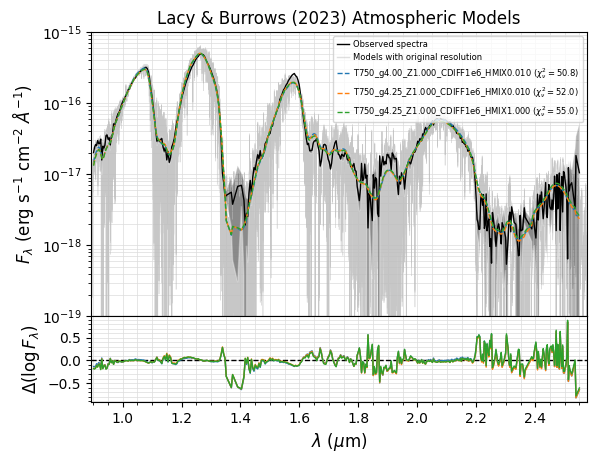

In [10]:
# using default logarithmic scale for fluxes
chi2_pickle_file = 'LB23_chi2_minimization_single_spectrum.pickle'
fig, ax = seda.plots.plot_chi2_fit(chi2_pickle_file, N_best_fits=3, 
                                   yrange=[1e-19, 1e-15], ori_res=True)

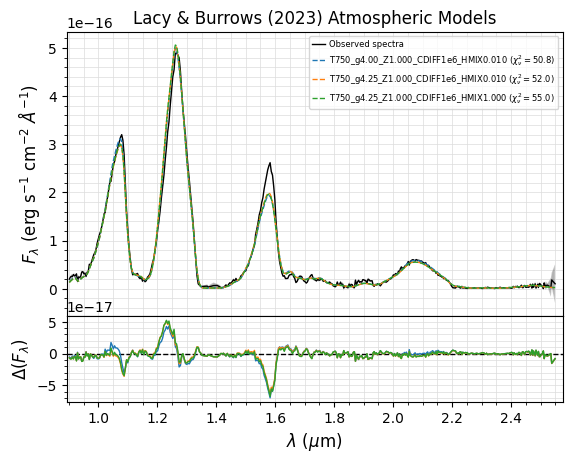

In [11]:
# considering fluxes in linear scale
fig, ax = seda.plots.plot_chi2_fit(chi2_pickle_file, N_best_fits=3, ylog=False)

Reduced chi square against wavelength

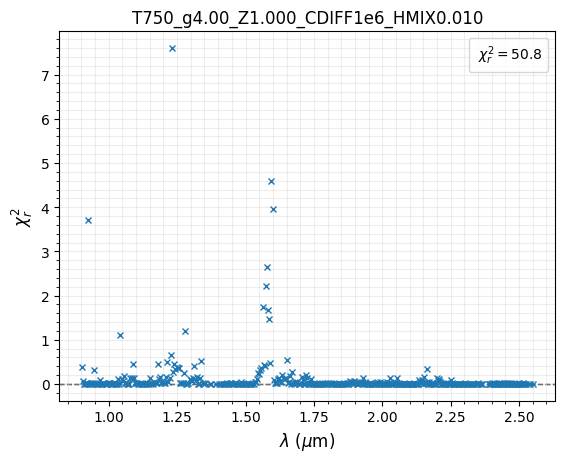

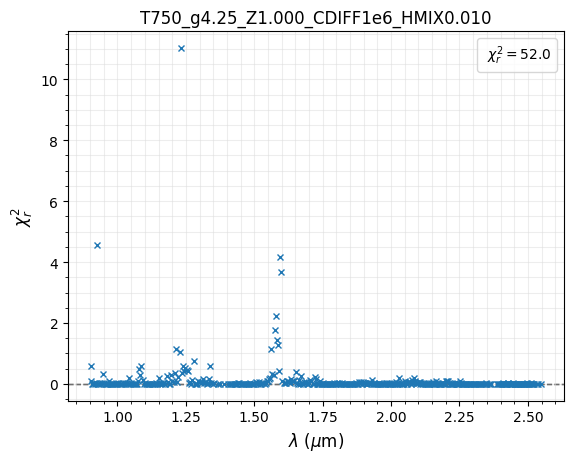

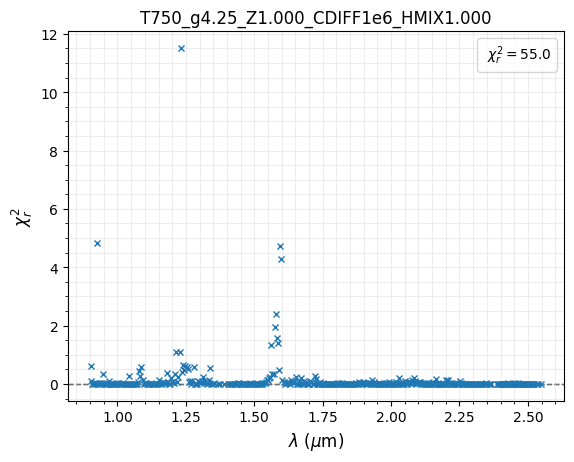

In [12]:
fig, ax = seda.plots.plot_chi2_red(chi2_pickle_file, N_best_fits=3)